# El Juego de los Números Uniformes
**Taller de Resolución de Problemas III — Universidad Austral — 2026**

Integrantes: (completar)

## Método de resolución

Resolvemos el problema de forma **analítica** y verificamos cada resultado con **simulación (Monte Carlo)**.

Lo hacemos en dos etapas:

1. **Etapa 1:** el Jugador 1 frente a un rival con un número uniforme (0,1), eligiendo para cada número la opción con mayor probabilidad de ganar.
2. **Etapa 2:** el juego completo, donde el Jugador 2 conoce la opción elegida por el Jugador 1 (pero no su número) y decide en consecuencia.

## Etapa 1: rival uniforme (0,1)

**Hipótesis:** el número final del rival es uniforme en (0,1). O sea, suponemos que el rival no elige nada: tiene un número al azar.

Nos toca un número $x$ y comparamos la probabilidad de ganar de cada opción:

- **Plantarse:** termino con $x$. Gano si el rival tiene menos que $x$ → $P = x$
- **Complementar:** termino con $1-x$. Gano si el rival tiene menos que $1-x$ → $P = 1-x$
- **Sortear de nuevo:** los dos tenemos un número al azar, cada uno gana la mitad de las veces → $P = 0.5$

**Ejemplos:**

- $x = 0.9$: plantarse 0.9, complementar 0.1, sortear 0.5 → **me planto**
- $x = 0.2$: plantarse 0.2, complementar 0.8, sortear 0.5 → **complemento**
- $x = 0.45$: plantarse 0.45, complementar 0.55, sortear 0.5 → **complemento** (por poco)

Entre $x$ y $1-x$, siempre uno de los dos es al menos 0.5. Entonces **sortear nunca conviene**.

**Estrategia:** me planto si $x \geq 0.5$ y complemento si $x < 0.5$. Siempre termino con $\max(x, 1-x)$.

### Reproducibilidad de los experimentos

Fijamos la semilla aleatoria en **2026** para poder reproducir los experimentos: si ejecutamos todas las celdas desde el comienzo y en el mismo orden, obtendremos los mismos números pseudoaleatorios. La semilla no elimina el error de Monte Carlo; solo permite repetirlo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Semilla fija para reproducir las simulaciones
np.random.seed(2026)

In [2]:
def mejor_opcion(x):
    p_plantarse = x
    p_complementar = 1 - x
    p_sortear = 0.5

    if p_plantarse >= p_complementar and p_plantarse >= p_sortear:
        return "plantarse", p_plantarse
    elif p_complementar >= p_sortear:
        return "complementar", p_complementar
    else:
        return "sortear", p_sortear

In [3]:
for x in [0.9, 0.2, 0.45, 0.5, 0.6]:
    opcion, prob = mejor_opcion(x)
    print("x =", x, "→", opcion, "con P(ganar) =", round(prob, 2))

x = 0.9 → plantarse con P(ganar) = 0.9
x = 0.2 → complementar con P(ganar) = 0.8
x = 0.45 → complementar con P(ganar) = 0.55
x = 0.5 → plantarse con P(ganar) = 0.5
x = 0.6 → plantarse con P(ganar) = 0.6


### Visualización de los intervalos de decisión

Comparamos las tres probabilidades de ganar para cada valor inicial de $x$. Las zonas sombreadas muestran dónde es preferible complementar y dónde plantarse. La línea negra marca la mejor probabilidad posible en este **modelo simplificado**.

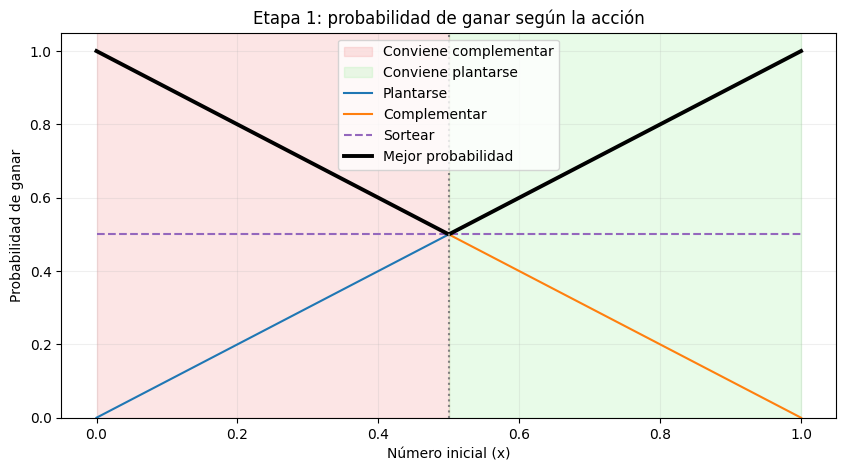

In [4]:
# Probabilidades de las tres acciones
valores_x = np.linspace(0, 1, 1000)
p_plantarse = valores_x
p_complementar = 1 - valores_x
p_sortear = np.full_like(valores_x, 0.5)
p_mejor = np.maximum(p_plantarse, p_complementar)

plt.figure(figsize=(10, 5))
plt.axvspan(0, 0.5, color="lightcoral", alpha=0.2, label="Conviene complementar")
plt.axvspan(0.5, 1, color="lightgreen", alpha=0.2, label="Conviene plantarse")
plt.plot(valores_x, p_plantarse, label="Plantarse", color="tab:blue")
plt.plot(valores_x, p_complementar, label="Complementar", color="tab:orange")
plt.plot(valores_x, p_sortear, "--", label="Sortear", color="tab:purple")
plt.plot(valores_x, p_mejor, color="black", linewidth=2.8, label="Mejor probabilidad")
plt.axvline(0.5, color="gray", linestyle=":")
plt.xlabel("Número inicial (x)")
plt.ylabel("Probabilidad de ganar")
plt.title("Etapa 1: probabilidad de ganar según la acción")
plt.ylim(0, 1.05)
plt.legend(loc="best")
plt.grid(alpha=0.2)
plt.show()

**Lectura del gráfico:** si $x<0.5$, complementar supera a las otras acciones; si $x>0.5$, conviene plantarse. Cuando $x=0.5$, las tres opciones empatan en probabilidad de victoria $0.5$. No aparece un intervalo intermedio en el que volver a sortear sea estrictamente mejor.

### Verificación por simulación

Para un número fijo $x$, jugamos muchas veces contra un rival uniforme (0,1) y contamos cuántas veces gana cada opción. Si las cuentas están bien, tiene que dar cerca de $x$, $1-x$ y $0.5$.

In [5]:
def simular_opciones(x, n):
    rival = np.random.rand(n)            # números del rival, uniformes (0,1)
    nuevo = np.random.rand(n)            # número nuevo si sorteo

    gana_plantarse = np.mean(x > rival)
    gana_complementar = np.mean(1 - x > rival)
    gana_sortear = np.mean(nuevo > rival)

    return gana_plantarse, gana_complementar, gana_sortear

for x in [0.9, 0.2, 0.45]:
    p1, p2, p3 = simular_opciones(x, 100000)
    print("x =", x, "| plantarse:", round(p1, 3), "| complementar:", round(p2, 3), "| sortear:", round(p3, 3))

x = 0.9 | plantarse: 0.901 | complementar: 0.101 | sortear: 0.499
x = 0.2 | plantarse: 0.201 | complementar: 0.8 | sortear: 0.5
x = 0.45 | plantarse: 0.452 | complementar: 0.549 | sortear: 0.5


### Comparación de la teoría con la simulación

Para algunos valores fijos de $x$, comparamos la probabilidad matemática de cada acción con la estimación de Monte Carlo. Las diferencias pequeñas son producto del azar de las simulaciones.

In [6]:
n_verificacion = 100000
print(f"{'x':>5} {'Acción':>14} {'Teórica':>10} {'Simulada':>10} {'Diferencia':>12}")
for x in [0.1, 0.25, 0.45, 0.5, 0.7, 0.9]:
    estimadas = simular_opciones(x, n_verificacion)
    teoricas = [x, 1 - x, 0.5]
    for nombre, teorica, estimada in zip(["Plantarse", "Complementar", "Sortear"], teoricas, estimadas):
        print(f"{x:5.2f} {nombre:>14} {teorica:10.4f} {estimada:10.4f} {abs(teorica-estimada):12.4f}")

    x         Acción    Teórica   Simulada   Diferencia
 0.10      Plantarse     0.1000     0.1012       0.0012
 0.10   Complementar     0.9000     0.8990       0.0010
 0.10        Sortear     0.5000     0.5014       0.0014
 0.25      Plantarse     0.2500     0.2487       0.0013
 0.25   Complementar     0.7500     0.7514       0.0014
 0.25        Sortear     0.5000     0.5001       0.0001
 0.45      Plantarse     0.4500     0.4480       0.0020
 0.45   Complementar     0.5500     0.5487       0.0013
 0.45        Sortear     0.5000     0.4979       0.0021
 0.50      Plantarse     0.5000     0.4991       0.0009
 0.50   Complementar     0.5000     0.4991       0.0009
 0.50        Sortear     0.5000     0.4995       0.0005
 0.70      Plantarse     0.7000     0.6992       0.0008
 0.70   Complementar     0.3000     0.3001       0.0001
 0.70        Sortear     0.5000     0.4995       0.0005
 0.90      Plantarse     0.9000     0.8981       0.0019
 0.90   Complementar     0.1000     0.1001      

### Probabilidad total de ganar con esta estrategia

Siempre termino con $\max(x, 1-x)$, que es un número entre 0.5 y 1, y gano con esa misma probabilidad. En promedio:

$$P(\text{ganar}) = E[\max(x, 1-x)] = 0.75$$

Lo comprobamos simulando partidas completas:

In [7]:
def jugar_etapa1(n):
    x = np.random.rand(n)
    mi_numero = np.maximum(x, 1 - x)     # me planto o complemento, el mayor
    rival = np.random.rand(n)
    return np.mean(mi_numero > rival)

print("P(ganar) simulada:", round(jugar_etapa1(1000000), 4))

P(ganar) simulada: 0.7504


### Comparación de tres estrategias mediante Monte Carlo

Simulamos **100.000 partidas** contra el mismo tipo de rival uniforme sin estrategia. Contrastamos tres maneras de actuar: (1) plantarse siempre, (2) volver a sortear siempre y (3) elegir matemáticamente el mayor de $x$ y $1-x$. En cada simulación utilizamos el **mismo número del rival** para hacer comparable el experimento.

Esperamos aproximadamente **50%**, **50%** y **75%**, respectivamente.

Plantarse: 49.97%
Sortear: 49.84%
Matemática: 74.94%


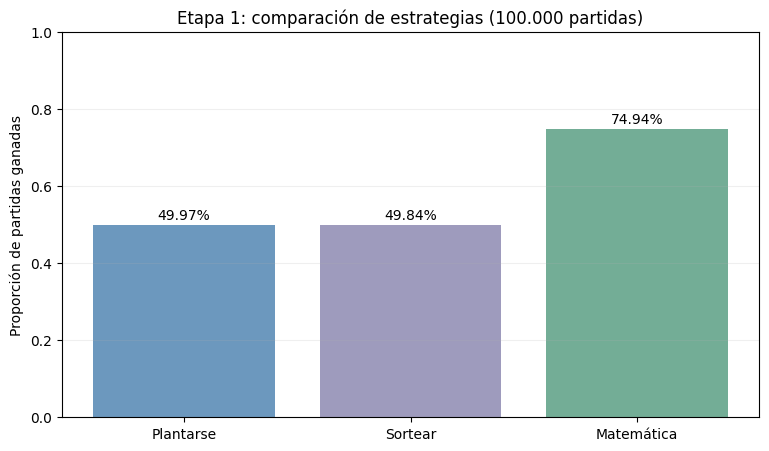

In [8]:
n_comparacion = 100000
x_comp = np.random.rand(n_comparacion)
rival_comp = np.random.rand(n_comparacion)
nuevo_comp = np.random.rand(n_comparacion)

p_siempre_plantarse = np.mean(x_comp > rival_comp)
p_siempre_sortear = np.mean(nuevo_comp > rival_comp)
p_matematica = np.mean(np.maximum(x_comp, 1-x_comp) > rival_comp)

nombres = ["Plantarse", "Sortear", "Matemática"]
resultados_comparacion = [p_siempre_plantarse, p_siempre_sortear, p_matematica]
for nombre, resultado in zip(nombres, resultados_comparacion):
    print(f"{nombre}: {resultado*100:.2f}%")

plt.figure(figsize=(9, 5))
barras = plt.bar(nombres, resultados_comparacion, color=["#6c98be", "#9e9bbd", "#73ad96"])
for barra, resultado in zip(barras, resultados_comparacion):
    plt.text(barra.get_x()+barra.get_width()/2, barra.get_height()+0.015,
             f"{resultado*100:.2f}%", ha="center")
plt.ylim(0, 1)
plt.ylabel("Proporción de partidas ganadas")
plt.title("Etapa 1: comparación de estrategias (100.000 partidas)")
plt.grid(axis="y", alpha=0.2)
plt.show()

**Interpretación:** plantarse o volver a sortear sin utilizar la información de $x$ produce cerca de un 50% de victorias, mientras que elegir entre complementar y plantarse según $x$ produce cerca del 75%. Esta comparación **no** resuelve todavía el juego estratégico completo.

### Convergencia de Monte Carlo

Comparamos la proporción de victorias de la estrategia matemática con el valor teórico de $0.75$ al aumentar las partidas (100, 1.000, 10.000 y 100.000). El resultado **no tiene por qué acercarse de forma monótona** en cada prueba, pero la incertidumbre estadística típica disminuye cuando aumenta el tamaño de la muestra.

100 partidas: 75.00%
1,000 partidas: 74.70%
10,000 partidas: 74.83%
100,000 partidas: 74.88%


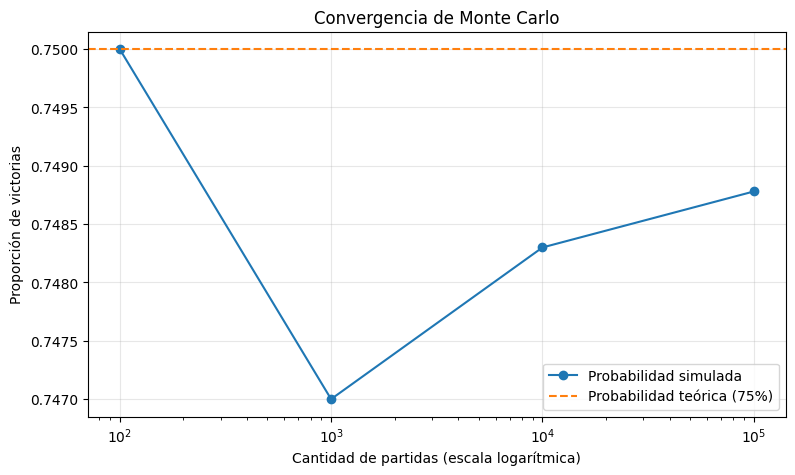

In [9]:
cantidades = [100, 1000, 10000, 100000]
resultados_convergencia = []
for cantidad in cantidades:
    probabilidad = jugar_etapa1(cantidad)
    resultados_convergencia.append(probabilidad)
    print(f"{cantidad:,} partidas: {probabilidad*100:.2f}%")

plt.figure(figsize=(9, 5))
plt.plot(cantidades, resultados_convergencia, marker="o", label="Probabilidad simulada")
plt.axhline(0.75, color="tab:orange", linestyle="--", label="Probabilidad teórica (75%)")
plt.xscale("log")
plt.xlabel("Cantidad de partidas (escala logarítmica)")
plt.ylabel("Proporción de victorias")
plt.title("Convergencia de Monte Carlo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Margen de error e intervalo de confianza aproximado del 95%

La estimación de Monte Carlo tiene variabilidad. Si $\hat p$ es la proporción de partidas ganadas y $n$ la cantidad de partidas, estimamos su error estándar y un margen de error aproximado del 95% con:

$$EE=\sqrt{\frac{\hat p(1-\hat p)}{n}},\qquad ME_{95\%}=1.96\cdot EE.$$

Esto supone partidas independientes con la misma estrategia. El margen se refiere al **azar de la simulación**, no a errores del modelo ni a la validez de la estrategia para el juego original.

In [10]:
n_error = 100000
p_estimada = jugar_etapa1(n_error)
error_estandar = np.sqrt(p_estimada * (1 - p_estimada) / n_error)
margen_95 = 1.96 * error_estandar
limite_inferior = p_estimada - margen_95
limite_superior = p_estimada + margen_95

print(f"Probabilidad estimada: {p_estimada:.4f} ({p_estimada*100:.2f}%)")
print(f"Error estándar: {error_estandar:.5f}")
print(f"Margen de error aproximado (95%): ±{margen_95:.4f} (±{margen_95*100:.2f} puntos porcentuales)")
print(f"Intervalo aproximado del 95%: [{limite_inferior:.4f}, {limite_superior:.4f}]")

Probabilidad estimada: 0.7502 (75.02%)
Error estándar: 0.00137
Margen de error aproximado (95%): ±0.0027 (±0.27 puntos porcentuales)
Intervalo aproximado del 95%: [0.7475, 0.7528]


### Demostración matemática del 75% mediante integrales

La estrategia que maximiza la probabilidad contra un rival uniforme consiste en complementar si $x<0.5$ y plantarse si $x\geq 0.5$. Dado que $X\sim U(0,1)$:

$$P(\text{ganar})=\int_0^{0.5}(1-x)\,dx+\int_{0.5}^{1}x\,dx=0.375+0.375=0.75.$$

Calculamos ambas integrales numéricamente para confirmar el resultado exacto.

In [11]:
from scipy.integrate import quad

parte1, _ = quad(lambda x: 1 - x, 0, 0.5)
parte2, _ = quad(lambda x: x, 0.5, 1)
probabilidad_total = parte1 + parte2

print("Primera integral (complementar):", parte1)
print("Segunda integral (plantarse):", parte2)
print("Probabilidad total:", probabilidad_total)
print("Porcentaje:", probabilidad_total * 100, "%")

Primera integral (complementar): 0.375
Segunda integral (plantarse): 0.375
Probabilidad total: 0.75
Porcentaje: 75.0 %


### ¿Por qué aparece 0,75? Distribución del número final

Después de elegir entre plantarse y complementar, el número final es $Y=\max(X,1-X)$. Siempre queda entre $0.5$ y $1$. Además, $Y$ es **uniforme en $(0.5,1)$**: para cada valor interior del intervalo existen dos valores iniciales simétricos que lo producen.

Por eso, su promedio es:

$$E[Y]=\frac{0.5+1}{2}=0.75.$$

Y como contra un rival $U(0,1)$ la probabilidad de ganar con número final $y$ es $y$, tenemos $P(\text{ganar})=E[Y]=0.75$. El siguiente histograma permite ver esa distribución aproximadamente uniforme.

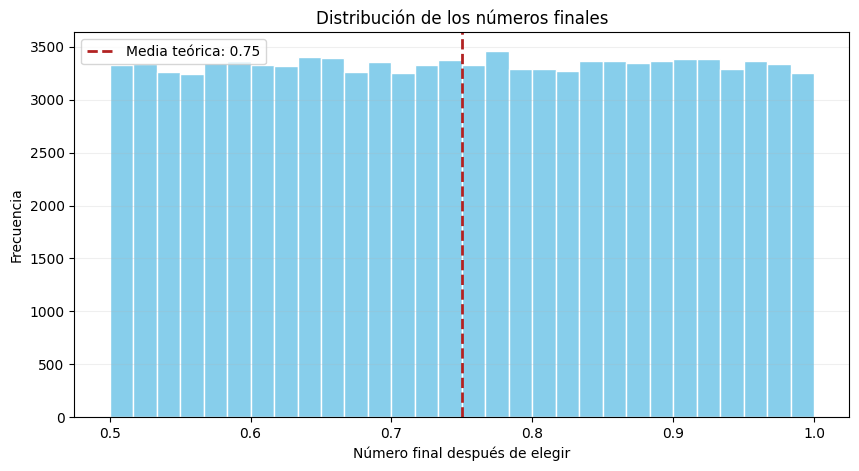

Promedio simulado de los números finales: 0.7502
Promedio teórico: 0.75


In [12]:
n_histograma = 100000
numeros_iniciales = np.random.rand(n_histograma)
numeros_finales = np.maximum(numeros_iniciales, 1 - numeros_iniciales)
promedio_histograma = np.mean(numeros_finales)

plt.figure(figsize=(10, 5))
plt.hist(numeros_finales, bins=30, range=(0.5, 1), color="skyblue", edgecolor="white")
plt.axvline(0.75, color="firebrick", linestyle="--", linewidth=2,
            label="Media teórica: 0.75")
plt.xlabel("Número final después de elegir")
plt.ylabel("Frecuencia")
plt.title("Distribución de los números finales")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.show()

print(f"Promedio simulado de los números finales: {promedio_histograma:.4f}")
print("Promedio teórico:", 0.75)

### Resumen de la Etapa 1: teoría frente a simulación

Para comparar los resultados con un mismo tamaño de muestra, usamos la simulación de **100.000 partidas** de la sección «Margen de error» (variable `p_estimada`).

In [13]:
print("RESUMEN FINAL — ETAPA 1")
print("Modelo: rival con número Uniforme(0,1), sin estrategia")
print("Decisión si x < 0.5: complementar")
print("Decisión si x > 0.5: plantarse")
print("Si x = 0.5: empate entre las tres acciones")
print(f"Probabilidad teórica: {probabilidad_total*100:.2f}%")
print(f"Probabilidad simulada: {p_estimada*100:.2f}%")
print(f"Diferencia absoluta: {abs(p_estimada-probabilidad_total)*100:.2f} puntos porcentuales")
print(f"Margen de error aproximado (95%): ±{margen_95*100:.2f} puntos porcentuales")

RESUMEN FINAL — ETAPA 1
Modelo: rival con número Uniforme(0,1), sin estrategia
Decisión si x < 0.5: complementar
Decisión si x > 0.5: plantarse
Si x = 0.5: empate entre las tres acciones
Probabilidad teórica: 75.00%
Probabilidad simulada: 75.02%
Diferencia absoluta: 0.02 puntos porcentuales
Margen de error aproximado (95%): ±0.27 puntos porcentuales


**Conclusión de la Etapa 1.** El método analítico entrega una probabilidad exacta de victoria de **75%** frente a un rival que conserva su número uniforme. Las simulaciones, el margen de error, el gráfico de convergencia y el histograma apoyan y explican ese resultado. La semilla fija hace reproducibles los experimentos. La siguiente etapa deberá analizar el juego original, en el que el rival también decide y conoce la acción anunciada por el primer jugador.

### ¿Qué falla de esta etapa?

El resultado dice que ganamos el 75% de las veces, pero **el rival también puede elegir**. Si el Jugador 2 usa la misma estrategia, cada uno gana el 50%. Entonces el supuesto "rival uniforme (0,1)" no es realista: el rival también se queda con su mayor número, que está entre 0.5 y 1.

En la etapa 2 incorporamos la decisión del Jugador 2, que además conoce la opción que eligió el Jugador 1.